In [ ]:
!pip install tensorflow tensorflow-hub ultralytics \
    torch torchvision torchmetrics pycocotools \
    opencv-python matplotlib seaborn pandas \
    lxml tqdm -q

In [ ]:
import os
import cv2
import time
import torch
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_hub as hub
import matplotlib.pyplot as plt

from PIL import Image
from tqdm import tqdm
from ultralytics import YOLO

from torchvision.datasets import VOCDetection
from torchmetrics.detection.mean_ap import MeanAveragePrecision

print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print("GPU Available:", torch.cuda.is_available())

TensorFlow: 2.21.0
PyTorch: 2.11.0+cu130
GPU Available: True


In [ ]:
# Download Pascal VOC 2007 dataset

train_dataset = VOCDetection(
    root="./data",
    year="2007",
    image_set="trainval",
    download=True
)

test_dataset = VOCDetection(
    root="./data",
    year="2007",
    image_set="test",
    download=True
)

print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))

Training Images: 5011
Testing Images: 4952


In [ ]:
VOC_CLASSES = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike",
    "person", "pottedplant", "sheep", "sofa",
    "train", "tvmonitor"
]

class_to_id = {
    name: i for i, name in enumerate(VOC_CLASSES)
}

id_to_class = {
    i: name for i, name in enumerate(VOC_CLASSES)
}

print("Total Classes:", len(VOC_CLASSES))
print(class_to_id)

Total Classes: 20
{'aeroplane': 0, 'bicycle': 1, 'bird': 2, 'boat': 3, 'bottle': 4, 'bus': 5, 'car': 6, 'cat': 7, 'chair': 8, 'cow': 9, 'diningtable': 10, 'dog': 11, 'horse': 12, 'motorbike': 13, 'person': 14, 'pottedplant': 15, 'sheep': 16, 'sofa': 17, 'train': 18, 'tvmonitor': 19}


In [ ]:
def get_voc_annotations(annotation):

    objects = annotation['annotation']['object']

    if not isinstance(objects, list):
        objects = [objects]

    boxes = []
    labels = []

    for obj in objects:

        class_name = obj['name']

        if class_name not in class_to_id:
            continue

        bbox = obj['bndbox']

        xmin = float(bbox['xmin'])
        ymin = float(bbox['ymin'])
        xmax = float(bbox['xmax'])
        ymax = float(bbox['ymax'])

        if xmax <= xmin or ymax <= ymin:
            continue

        boxes.append([xmin, ymin, xmax, ymax])
        labels.append(class_to_id[class_name])

    return (
        np.array(boxes, dtype=np.float32).reshape(-1, 4),
        np.array(labels, dtype=np.int64)
    )

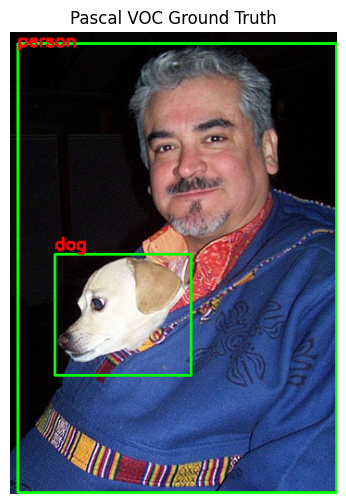

In [ ]:
def show_voc_image(index):

    image, annotation = test_dataset[index]

    image = np.array(image.convert("RGB"))

    boxes, labels = get_voc_annotations(annotation)

    for box, label in zip(boxes, labels):

        x1, y1, x2, y2 = box.astype(int)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            image,
            id_to_class[label],
            (x1, max(15, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.title("Pascal VOC Ground Truth")
    plt.axis("off")
    plt.show()


show_voc_image(0)

In [ ]:
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

faster_rcnn = fasterrcnn_resnet50_fpn(
    weights=weights
)

faster_rcnn.eval()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

faster_rcnn.to(device)

# COCO class names
COCO_CLASSES = weights.meta["categories"]

print("Faster R-CNN Loaded Successfully")

Faster R-CNN Loaded Successfully


In [ ]:
yolo_model = YOLO("yolov8n.pt")

print("YOLOv8 Loaded Successfully")

YOLOv8 Loaded Successfully


In [ ]:
# Load pretrained SSD MobileNet V2 from TensorFlow Hub
ssd_model = hub.load(
    "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"
)

# The signature may be named "serving_default", not "default".
available_signatures = list(ssd_model.signatures.keys())
print("Available SSD signatures:", available_signatures)

if not available_signatures:
    raise RuntimeError("The loaded SSD model has no callable signatures.")

signature_name = (
    "serving_default"
    if "serving_default" in available_signatures
    else available_signatures[0]
)
ssd_detector = ssd_model.signatures[signature_name]

# Read the actual input name and dtype from the model signature.
_, ssd_input_specs = ssd_detector.structured_input_signature
ssd_input_name = next(iter(ssd_input_specs))
ssd_input_spec = ssd_input_specs[ssd_input_name]

print("SSD MobileNet Loaded Successfully")
print("Selected signature:", signature_name)
print("Input name:", ssd_input_name)
print("Input dtype:", ssd_input_spec.dtype)
print("Output keys:", list(ssd_detector.structured_outputs.keys()))

Available SSD signatures: ['serving_default']
SSD MobileNet Loaded Successfully
Selected signature: serving_default
Input name: input_tensor
Input dtype: <dtype: 'uint8'>
Output keys: ['detection_scores', 'num_detections', 'raw_detection_scores', 'detection_classes', 'detection_anchor_indices', 'raw_detection_boxes', 'detection_boxes', 'detection_multiclass_scores']


In [ ]:
def map_coco_to_voc(class_name):

    name = class_name.lower().strip()

    mapping = {
        "airplane": "aeroplane",
        "motorcycle": "motorbike",
        "dining table": "diningtable",
        "potted plant": "pottedplant",
        "tv": "tvmonitor",
        "couch": "sofa"
    }

    name = mapping.get(name, name)

    if name in class_to_id:
        return class_to_id[name]

    return None

In [ ]:
def detect_faster_rcnn(image):

    image_rgb = np.array(image.convert("RGB"))

    tensor = torch.from_numpy(
        image_rgb
    ).permute(2, 0, 1).float() / 255.0

    tensor = tensor.to(device)

    start = time.perf_counter()

    with torch.no_grad():
        output = faster_rcnn([tensor])[0]

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    boxes = output["boxes"].cpu().numpy()
    scores = output["scores"].cpu().numpy()
    labels = output["labels"].cpu().numpy()

    detections = []

    for box, score, label in zip(boxes, scores, labels):

        if score < 0.5:
            continue

        coco_name = COCO_CLASSES[label]

        voc_label = map_coco_to_voc(coco_name)

        if voc_label is None:
            continue

        detections.append({
            "box": box,
            "score": float(score),
            "label": voc_label
        })

    return detections, elapsed

In [ ]:
def detect_yolo(image):

    image_rgb = np.array(image.convert("RGB"))

    start = time.perf_counter()

    result = yolo_model.predict(
        image_rgb,
        conf=0.5,
        verbose=False
    )[0]

    elapsed = time.perf_counter() - start

    detections = []

    if result.boxes is not None:

        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()
        labels = result.boxes.cls.cpu().numpy().astype(int)

        for box, score, label in zip(boxes, scores, labels):

            coco_name = yolo_model.names[label]

            voc_label = map_coco_to_voc(coco_name)

            if voc_label is None:
                continue

            detections.append({
                "box": box,
                "score": float(score),
                "label": voc_label
            })

    return detections, elapsed

In [ ]:
# COCO category IDs used by the pretrained SSD MobileNet model.
# These are mapped to the matching Pascal VOC class labels.
COCO_ID_TO_VOC = {
    1: "person",
    2: "bicycle",
    3: "car",
    4: "motorbike",
    5: "aeroplane",
    6: "bus",
    7: "train",
    9: "boat",
    16: "bird",
    17: "cat",
    18: "dog",
    19: "horse",
    20: "sheep",
    21: "cow",
    44: "bottle",
    62: "chair",
    63: "sofa",
    64: "pottedplant",
    67: "diningtable",
    72: "tvmonitor"
}

def detect_ssd(image):
    image_rgb = np.array(image.convert("RGB"))

    # Use the dtype and input name required by this SavedModel.
    input_tensor = tf.convert_to_tensor(
        image_rgb,
        dtype=ssd_input_spec.dtype
    )
    input_tensor = tf.expand_dims(input_tensor, axis=0)

    start = time.perf_counter()
    output = ssd_detector(**{ssd_input_name: input_tensor})

    # Ensure inference has completed before measuring elapsed time.
    output["detection_scores"].numpy()
    elapsed = time.perf_counter() - start

    boxes = output["detection_boxes"][0].numpy()
    scores = output["detection_scores"][0].numpy()

    # Output class information differs between TensorFlow Hub exports.
    if "detection_class_entities" in output:
        class_values = output["detection_class_entities"][0].numpy()
        class_values_are_names = True
    elif "detection_class_names" in output:
        class_values = output["detection_class_names"][0].numpy()
        class_values_are_names = True
    elif "detection_classes" in output:
        class_values = output["detection_classes"][0].numpy()
        class_values_are_names = False
    else:
        raise KeyError(
            "No class information in SSD output. Available keys: "
            + str(list(output.keys()))
        )

    detections = []
    height, width = image_rgb.shape[:2]

    for box, score, class_value in zip(boxes, scores, class_values):
        if float(score) < 0.5:
            continue

        if class_values_are_names:
            if isinstance(class_value, bytes):
                class_name = class_value.decode("utf-8")
            else:
                class_name = str(class_value)
            voc_label = map_coco_to_voc(class_name)
        else:
            coco_id = int(class_value)
            voc_name = COCO_ID_TO_VOC.get(coco_id)
            voc_label = (
                class_to_id.get(voc_name)
                if voc_name is not None else None
            )

        if voc_label is None:
            continue

        ymin, xmin, ymax, xmax = box
        detections.append({
            "box": np.array([
                xmin * width,
                ymin * height,
                xmax * width,
                ymax * height
            ]),
            "score": float(score),
            "label": voc_label
        })

    return detections, elapsed

In [ ]:
image, annotation = test_dataset[10]

models_detection = {
    "Faster R-CNN": detect_faster_rcnn,
    "YOLOv8": detect_yolo,
    "SSD MobileNet": detect_ssd
}

In [ ]:
def visualize_detections(image, detections, title):

    image = np.array(image.convert("RGB")).copy()

    for det in detections:

        x1, y1, x2, y2 = map(
            int, det["box"]
        )

        label = id_to_class[det["label"]]

        score = det["score"]

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        text = f"{label}: {score:.2f}"

        cv2.putText(
            image,
            text,
            (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            2
        )

    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")
    plt.show()


Model: Faster R-CNN
Detected Objects: 1
Inference Time: 0.2134 seconds


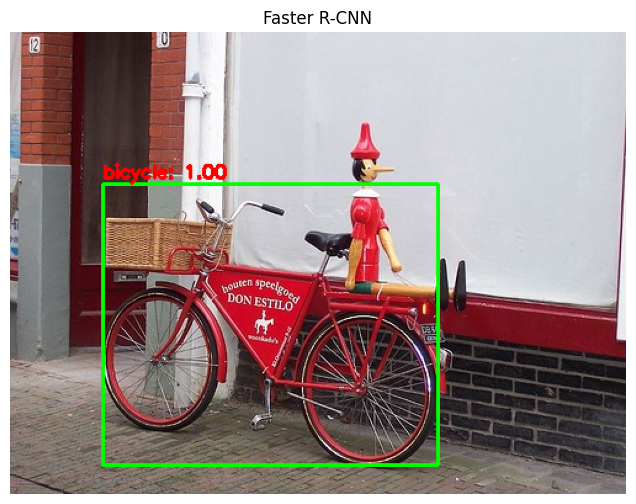


Model: YOLOv8
Detected Objects: 1
Inference Time: 0.1164 seconds


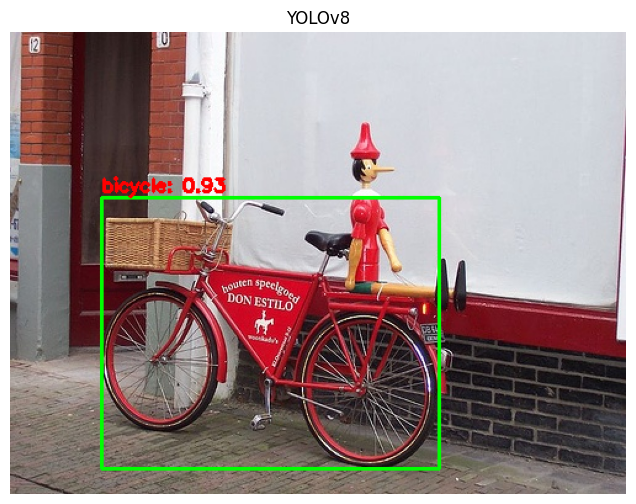


Model: SSD MobileNet
Detected Objects: 2
Inference Time: 1.9393 seconds


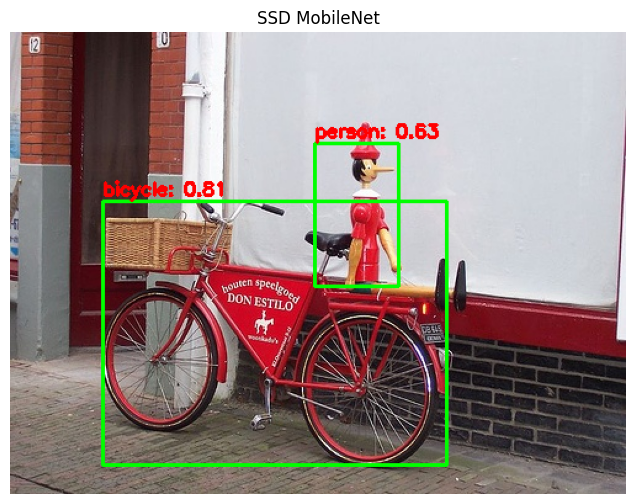

In [ ]:
for name, detector in models_detection.items():

    detections, inference_time = detector(image)

    print("\nModel:", name)
    print("Detected Objects:", len(detections))
    print("Inference Time:", round(inference_time, 4), "seconds")

    visualize_detections(
        image,
        detections,
        name
    )

In [ ]:
def prepare_ground_truth(annotation):

    boxes, labels = get_voc_annotations(annotation)

    # Pascal VOC coordinates are 1-based.
    # Convert them to zero-based coordinates.
    boxes[:, [0, 2]] -= 1
    boxes[:, [1, 3]] -= 1

    return {
        "boxes": torch.tensor(boxes, dtype=torch.float32),
        "labels": torch.tensor(labels, dtype=torch.int64)
    }


def prepare_predictions(detections):

    boxes = []
    labels = []
    scores = []

    for det in detections:

        boxes.append(det["box"])
        labels.append(det["label"])
        scores.append(det["score"])

    return {
        "boxes": torch.tensor(
            np.array(boxes).reshape(-1, 4),
            dtype=torch.float32
        ),
        "labels": torch.tensor(
            labels,
            dtype=torch.int64
        ),
        "scores": torch.tensor(
            scores,
            dtype=torch.float32
        )
    }

In [ ]:
N_EVAL = 200

evaluation_results = {}

for name, detector in models_detection.items():

    print("\nEvaluating:", name)

    metric = MeanAveragePrecision(
        box_format='xyxy',
        iou_type='bbox',
        iou_thresholds=[0.5]
    )

    total_time = 0

    for i in tqdm(range(N_EVAL)):

        image, annotation = test_dataset[i]

        detections, elapsed = detector(image)

        total_time += elapsed

        prediction = prepare_predictions(detections)

        target = prepare_ground_truth(annotation)

        metric.update([prediction], [target])

    scores = metric.compute()

    fps = N_EVAL / total_time if total_time > 0 else 0

    evaluation_results[name] = {
        "mAP@0.50": float(scores['map_50']),
        "mAP": float(scores['map']),
        "Inference Time": total_time / N_EVAL,
        "FPS": fps
    }

    print("mAP@0.50:", round(float(scores['map_50']), 4))
    print("FPS:", round(fps, 2))


Evaluating: Faster R-CNN


100%|██████████| 200/200 [00:34<00:00,  5.75it/s]


mAP@0.50: 0.7591
FPS: 6.02

Evaluating: YOLOv8


100%|██████████| 200/200 [00:02<00:00, 78.45it/s]


mAP@0.50: 0.5975
FPS: 104.81

Evaluating: SSD MobileNet


100%|██████████| 200/200 [00:11<00:00, 17.77it/s]


mAP@0.50: 0.6063
FPS: 20.19


In [ ]:
map_df = pd.DataFrame(evaluation_results).T

print("\nMODEL mAP COMPARISON")
print(map_df.round(4))


MODEL mAP COMPARISON
               mAP@0.50     mAP  Inference Time       FPS
Faster R-CNN     0.7591  0.7591          0.1660    6.0226
YOLOv8           0.5975  0.5975          0.0095  104.8136
SSD MobileNet    0.6063  0.6063          0.0495   20.1851


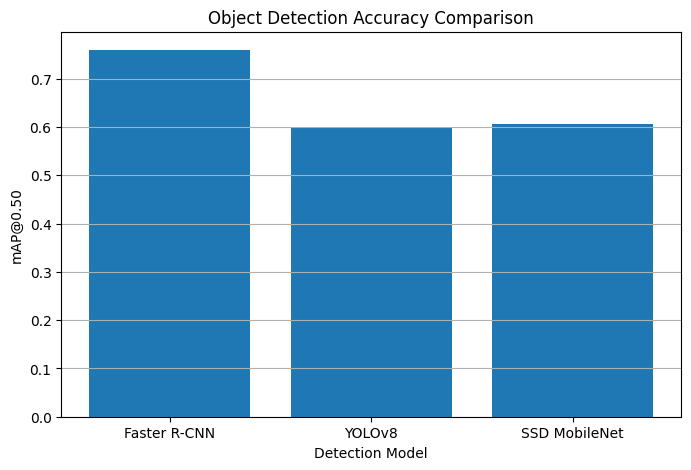

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    map_df.index,
    map_df["mAP@0.50"]
)

plt.title("Object Detection Accuracy Comparison")
plt.xlabel("Detection Model")
plt.ylabel("mAP@0.50")

plt.grid(axis='y')
plt.show()

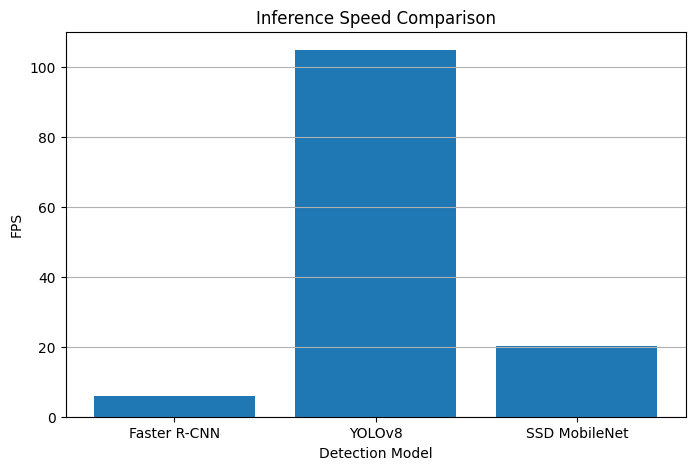

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    map_df.index,
    map_df["FPS"]
)

plt.title("Inference Speed Comparison")
plt.xlabel("Detection Model")
plt.ylabel("FPS")

plt.grid(axis='y')
plt.show()

In [ ]:
model_parameters = {
    "Faster R-CNN": sum(
        p.numel() for p in faster_rcnn.parameters()
    ),

    "YOLOv8": sum(
        p.numel() for p in yolo_model.model.parameters()
    ),

    "SSD MobileNet": sum(
        np.prod(v.shape) for v in ssd_detector.variables
    )
}

for name, params in model_parameters.items():

    print(
        name,
        ":",
        f"{params / 1e6:.2f} Million Parameters"
    )

Faster R-CNN : 41.76 Million Parameters
YOLOv8 : 3.16 Million Parameters
SSD MobileNet : 6.10 Million Parameters


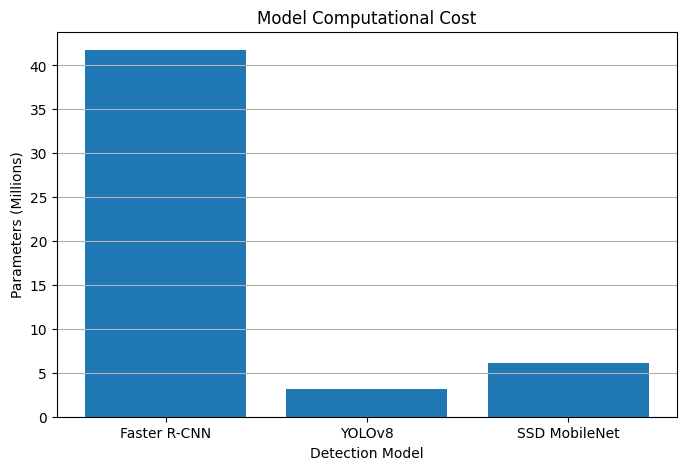

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_parameters.keys(),
    [v / 1e6 for v in model_parameters.values()]
)

plt.title("Model Computational Cost")
plt.xlabel("Detection Model")
plt.ylabel("Parameters (Millions)")

plt.grid(axis='y')
plt.show()

In [ ]:
from google.colab import files

uploaded = files.upload()

video_path = next(iter(uploaded.keys()))

print("Uploaded Video:", video_path)

#video_path = "input_video.mp4" for jupyter nb

Saving 13002160_1920_1080_60fps.mp4 to 13002160_1920_1080_60fps.mp4
Uploaded Video: 13002160_1920_1080_60fps.mp4


In [ ]:
def detect_video(video_path, detector, output_path):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise ValueError("Cannot open video file")

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    fps_original = cap.get(cv2.CAP_PROP_FPS)

    if fps_original <= 0:
        fps_original = 25

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')

    writer = cv2.VideoWriter(
        output_path,
        fourcc,
        fps_original,
        (width, height)
    )

    total_frames = 0
    total_inference_time = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        frame_rgb = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        image = Image.fromarray(frame_rgb)

        detections, elapsed = detector(image)

        total_inference_time += elapsed
        total_frames += 1

        # Draw bounding boxes
        for det in detections:

            x1, y1, x2, y2 = map(
                int, det["box"]
            )

            label = id_to_class[det["label"]]

            score = det["score"]

            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            cv2.putText(
                frame,
                f"{label}: {score:.2f}",
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

        current_fps = (
            1 / elapsed if elapsed > 0 else 0
        )

        cv2.putText(
            frame,
            f"Inference FPS: {current_fps:.2f}",
            (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 0, 255),
            2
        )

        writer.write(frame)

    cap.release()
    writer.release()

    average_fps = (
        total_frames / total_inference_time
        if total_inference_time > 0 else 0
    )

    print("Total Frames:", total_frames)
    print("Average Inference FPS:", round(average_fps, 2))
    print("Output Video:", output_path)

    return average_fps

In [ ]:
video_results = {}

for name, detector in models_detection.items():

    print("\nProcessing Video:", name)

    output_path = name.replace(" ", "_") + "_output.mp4"

    fps = detect_video(
        video_path,
        detector,
        output_path
    )

    video_results[name] = fps


Processing Video: Faster R-CNN
Total Frames: 1858
Average Inference FPS: 5.11
Output Video: Faster_R-CNN_output.mp4

Processing Video: YOLOv8
Total Frames: 1858
Average Inference FPS: 63.39
Output Video: YOLOv8_output.mp4

Processing Video: SSD MobileNet
Total Frames: 1858
Average Inference FPS: 19.05
Output Video: SSD_MobileNet_output.mp4


In [ ]:
from IPython.display import Video, display

display(
    Video(
        "YOLOv8_output.mp4",
        embed=True
    )
)

In [ ]:
from IPython.display import Video, display

display(Video("YOLOv8_output.mp4", embed=True))

Buffered data was truncated after reaching the output size limit.

In [ ]:
final_results = pd.DataFrame(evaluation_results).T

final_results["Parameters (Millions)"] = {
    name: value / 1e6
    for name, value in model_parameters.items()
}

print("\nFINAL OBJECT DETECTION COMPARISON")

print(final_results.round(4))


FINAL OBJECT DETECTION COMPARISON
               mAP@0.50     mAP  Inference Time       FPS  \
Faster R-CNN     0.7591  0.7591          0.1660    6.0226   
YOLOv8           0.5975  0.5975          0.0095  104.8136   
SSD MobileNet    0.6063  0.6063          0.0495   20.1851   

               Parameters (Millions)  
Faster R-CNN                 41.7553  
YOLOv8                        3.1572  
SSD MobileNet                 6.1040  
